# Comparing structural features to confidence scores

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm

In [2]:
confidence_scores = pd.read_csv('../data/processed/af3_confidence_scores.csv')
structural_features = pd.read_csv('../data/processed/af3_structural_features.csv')
entries = pd.read_csv('../data/interim/sequences_sample.csv')

entries = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='structure_name',
).merge(
    structural_features,
    how='inner',
    left_on=['index', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

In [3]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [4]:
scanning_angle = scipy.stats.norm(loc=67.9, scale=np.sqrt(202.1))
entries['scanning_angle_probability'] = entries['scanning_angle'].apply(scanning_angle.pdf)

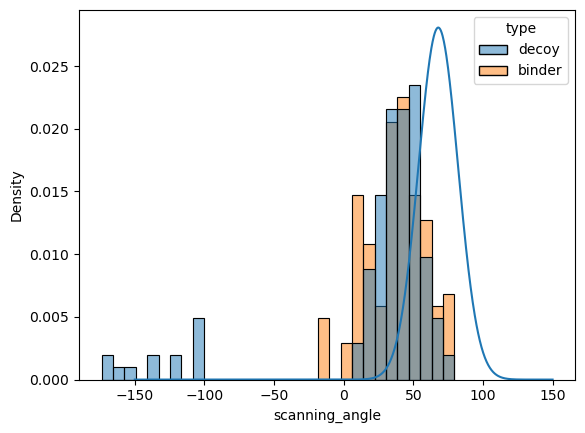

In [5]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(entries, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

In [6]:
pitch_angle = scipy.stats.gamma(a=1.20, loc=0.0365, scale=5.78)
entries['pitch_angle_probability'] = entries['pitch_angle'].apply(pitch_angle.pdf)

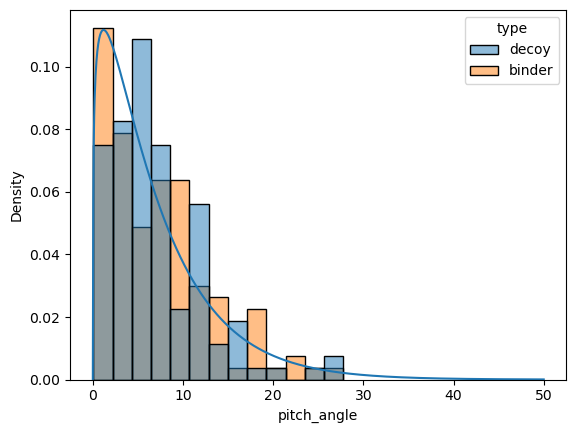

In [7]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(entries, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

In [8]:
def z_score(x: float | np.ndarray) -> float | np.ndarray:
    means = [27.05, 28.62]
    variances = [0.468, 0.908]
    weights = [0.434, 0.566]

    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)


entries['z_score_probability'] = entries['z_score'].apply(z_score)

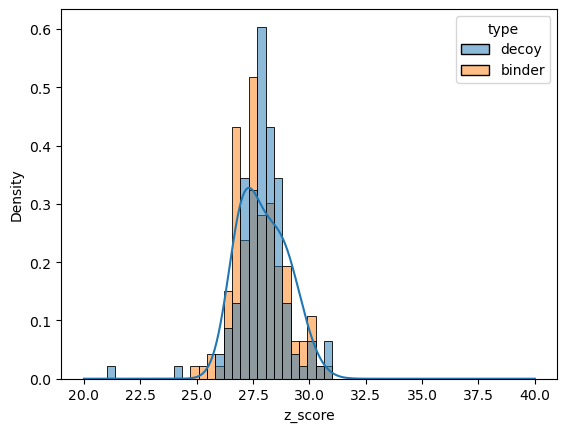

In [9]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x))

sns.histplot(entries, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [10]:
entries['log_probability'] = entries[
    ['scanning_angle_probability', 'pitch_angle_probability', 'z_score_probability']
].apply(lambda row: np.sum(np.log(row)), axis=1)

<Axes: xlabel='score', ylabel='probability'>

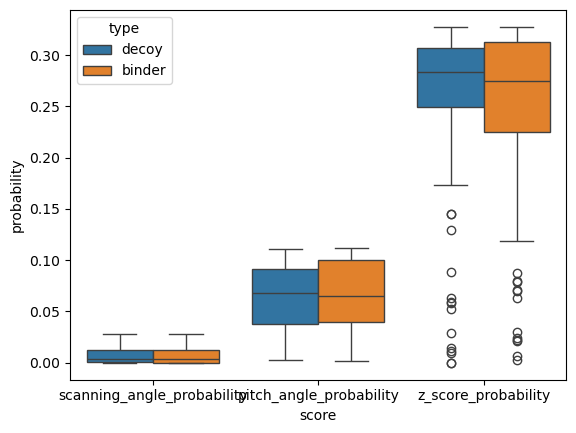

In [11]:
score_probabilities = entries.melt(
    id_vars=['type', 'label'],
    value_vars=['scanning_angle_probability', 'pitch_angle_probability', 'z_score_probability'],
    var_name='score',
    value_name='probability',
)
sns.boxplot(score_probabilities, x='score', y='probability', hue='type')

In [12]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability']))

pitch_angle_probability
0.49539200000000005
scanning_angle_probability
0.5110399999999999
z_score_probability
0.47622400000000004


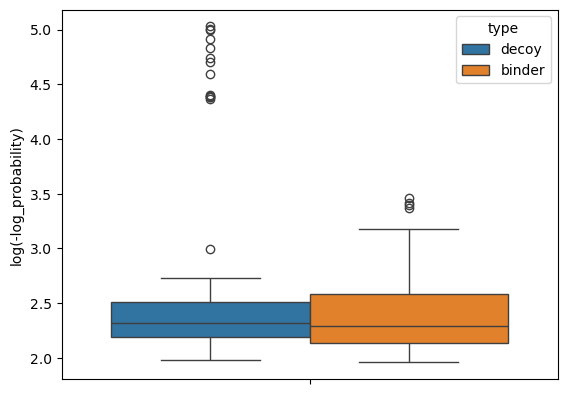

0.46470399999999995


In [13]:
sns.boxplot(y=np.log(-entries['log_probability']), hue=entries['type'])
plt.ylabel('log(-log_probability)')

plt.show()

print(sklearn.metrics.roc_auc_score(group['label'], np.log(-entries['log_probability'])))

In [14]:
confidence_columns = sorted(entries.filter(regex='pae|ptm').columns.tolist())
structural_columns = ['scanning_angle_probability', 'pitch_angle_probability', 'z_score_probability']



In [15]:
fig, axes = plt.subplots(
    len(confidence_columns), len(structural_columns), figsize=(5 * len(structural_columns), 5 * len(confidence_columns))
)

for i, confidence in enumerate(confidence_columns):
    for j, probability in enumerate(structural_columns):
        axes[i, j].plot(entries[probability], entries[confidence], 'o')

        reg = scipy.stats.linregress(entries[probability], entries[confidence])
        x = np.linspace(entries[probability].min(), entries[probability].max())
        y = reg.slope * x + reg.intercept

        axes[i, j].plot(x, y, 'r--')
        axes[i, j].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i, j].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

        axes[i, j].set_xlabel(probability)
        if j == 0:
            axes[i, j].set_ylabel(confidence)

        else:
            axes[i, j].set_yticklabels('')

In [16]:
best_r_squared = 0
best_reg = None
best_name = None

for confidence_column in confidence_columns:
    print(confidence_column)

    X = entries[structural_columns]
    y = entries[confidence_column]

    X = sm.add_constant(X)

    model = sm.OLS(y, X)
    reg = model.fit()

    if reg.rsquared > best_r_squared:
        best_r_squared = reg.rsquared
        best_reg = reg
        best_name = confidence_column

    print(reg.summary())
    print('\n\n')

print('==============================================================================================')
print('Best results:', best_name, 'R^2:', best_r_squared)
print('==============================================================================================')

print(best_reg.summary())

alpha_chain_alpha_chain_pae_min
                                   OLS Regression Results                                  
Dep. Variable:     alpha_chain_alpha_chain_pae_min   R-squared:                     -51.056
Model:                                         OLS   Adj. R-squared:                -51.691
Method:                              Least Squares   F-statistic:                    -80.42
Date:                             Wed, 25 Jun 2025   Prob (F-statistic):               1.00
Time:                                     09:55:13   Log-Likelihood:                 8335.4
No. Observations:                              250   AIC:                        -1.666e+04
Df Residuals:                                  246   BIC:                        -1.665e+04
Df Model:                                        3                                         
Covariance Type:                         nonrobust                                         
                                 coef    std err

                            OLS Regression Results                            
Dep. Variable:       mhc_chain_2_iptm   R-squared:                       0.026
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     2.231
Date:                Wed, 25 Jun 2025   Prob (F-statistic):             0.0852
Time:                        09:55:14   Log-Likelihood:                 314.51
No. Observations:                 250   AIC:                            -621.0
Df Residuals:                     246   BIC:                            -606.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               